# YouTube Shorts Virality — Exploratory Data Analysis

**Question:** What makes a YouTube Short go viral, and can we predict it early?

**Study design**
- **Population:** channels whose self-reported country is **US or CA**. Collection is worldwide; the filter is applied in this notebook.
- **Outcome:** a video is **viral** if its views at **72 hours** (nearest snapshot within ±2h) are in the **top 10%** of the study population.
- **Early prediction:** early features use only snapshots taken **at or before** the feature cutoff (6h by default), never after.
- **Data:** a point-in-time copy of the private `shorts-data` repo; collection is ongoing. The snapshot time printed below applies to every result.


| File | One row per | Contents |
|---|---|---|
| `data/channels.csv` | channel | title, creation date, subscribers, total views/videos (as of first sighting) |
| `data/videos.csv` | video | publish time, channel, title, description, duration, tags |
| `data/channel_countries.csv` | channel | self-reported channel country (not upload or audience location) |
| `data/observations/*.csv` | video × snapshot | views, likes, comments at a point in time (roughly hourly) |

In [27]:
from pathlib import Path
import json
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import average_precision_score, roc_auc_score

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

# Study design
STUDY_COUNTRIES = ["US", "CA"]   # channel's self-reported country
OUTCOME_HOURS = 72               # viral = top 10% of views at 72h
OUTCOME_TOL = 2                  # use the snapshot nearest 72h, if within ± this many hours
VIRAL_QUANTILE = 0.90
EARLY_HOURS = [1, 3, 6]
EARLY_WINDOW = 1                 # an "as of h" value is the latest snapshot with age in [h - 1, h]

VIRAL_COLOR, NONVIRAL_COLOR = "#eb6834", "#2a78d6"
BAR_COLOR = "#2a78d6"
LABEL_PALETTE = {True: VIRAL_COLOR, False: NONVIRAL_COLOR}
GROUP_COLORS = {"top 10%": VIRAL_COLOR, "bottom 90%": NONVIRAL_COLOR}

def parse_json_list(value):
    """Parse a JSON-list string, returning an empty list for missing or malformed values."""
    if not isinstance(value, str):
        return []
    try:
        parsed = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        return []
    return parsed if isinstance(parsed, list) else []

## Load the data

In [28]:
# Support launching Jupyter from either the repository root or project/.
PROJECT_DIR = Path.cwd() / "project" if (Path.cwd() / "project" / "EDA_final.ipynb").is_file() else Path.cwd()
DATA_DIR = PROJECT_DIR / "shorts-data-main" / "shorts-data-main" / "data"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Data folder not found: {DATA_DIR}")

def to_utc(values):
    # The collector writes ISO-8601 timestamps both with and without fractional seconds.
    # Without format="ISO8601", pandas infers one format and silently turns the rest into NaT.
    return pd.to_datetime(values, utc=True, format="ISO8601", errors="coerce")

videos = pd.read_csv(DATA_DIR / "videos.csv")
channels = pd.read_csv(DATA_DIR / "channels.csv")
countries = pd.read_csv(DATA_DIR / "channel_countries.csv")
snapshot_files = sorted((DATA_DIR / "observations").glob("*.csv"))

frames, manifest_rows = [], []
for path in snapshot_files:
    frame = pd.read_csv(path)
    frame["observed_at"] = to_utc(frame["observed_at"])
    manifest_rows.append({"snapshot_file": path.name, "rows": len(frame),
                          "started_at": frame["observed_at"].min(), "finished_at": frame["observed_at"].max()})
    frames.append(frame)
observations = pd.concat(frames, ignore_index=True)
snapshot_manifest = pd.DataFrame(manifest_rows).sort_values("started_at", ignore_index=True)
del frames

for col in ["first_seen_at", "published_at"]:
    videos[col] = to_utc(videos[col])
for col in ["first_seen_at", "channel_created_at"]:
    channels[col] = to_utc(channels[col])
countries["country_checked_at"] = to_utc(countries["country_checked_at"])
for col in ["age_hours", "view_count", "like_count", "comment_count"]:
    observations[col] = pd.to_numeric(observations[col], errors="coerce")
# Sort once so per-video differences below never need a sorted copy (1M+ rows).
observations.sort_values(["video_id", "observed_at"], inplace=True, ignore_index=True)

DATA_SNAPSHOT_AT = observations["observed_at"].max()
print(f"DATA SNAPSHOT: {DATA_SNAPSHOT_AT:%Y-%m-%d %H:%M} UTC (point-in-time copy; collection ongoing)")
print(f"data folder:   {DATA_DIR}")
print(f"videos:        {videos.shape}")
print(f"channels:      {channels.shape}")
print(f"countries:     {countries.shape}")
print(f"observations:  {observations.shape} from {len(snapshot_files)} snapshot files")
print(f"observations span {observations['observed_at'].min():%Y-%m-%d %H:%M} → {DATA_SNAPSHOT_AT:%Y-%m-%d %H:%M} UTC")

DATA SNAPSHOT: 2026-10-22 23:53 UTC (point-in-time copy; collection ongoing)
data folder:   c:\Users\shiva\Desktop\UW Courses\Erdos\data-science\project\shorts-data-main\shorts-data-main\data
videos:        (16959, 10)
channels:      (9664, 7)
countries:     (9662, 3)
observations:  (1124929, 6) from 247 snapshot files
observations span 2026-10-12 15:37 → 2026-10-22 23:53 UTC


In [29]:
EXPECTED_COLUMNS = {
    "videos": {"video_id", "first_seen_at", "published_at", "channel_id", "channel_title",
               "title", "description", "duration", "duration_seconds", "tags"},
    "channels": {"channel_id", "first_seen_at", "channel_title", "channel_created_at",
                 "total_channel_views", "subscriber_count", "total_channel_videos"},
    "countries": {"channel_id", "channel_country", "country_checked_at"},
    "observations": {"video_id", "observed_at", "age_hours", "view_count", "like_count", "comment_count"},
}
tables = {"videos": videos, "channels": channels, "countries": countries, "observations": observations}
for name, frame in tables.items():
    missing_cols = EXPECTED_COLUMNS[name] - set(frame.columns)
    extra_cols = set(frame.columns) - EXPECTED_COLUMNS[name]
    if missing_cols:
        raise ValueError(f"{name} is missing columns: {sorted(missing_cols)}")
    if extra_cols:
        print(f"{name} has new columns not in the documented schema: {sorted(extra_cols)}")

timestamp_nat = {
    f"{table}.{col}": int(tables[table][col].isna().sum())
    for table, cols in [("videos", ["first_seen_at", "published_at"]),
                        ("channels", ["first_seen_at", "channel_created_at"]),
                        ("countries", ["country_checked_at"]),
                        ("observations", ["observed_at"])]
    for col in cols
}
print("Missing or unparseable timestamps (should all be 0):", timestamp_nat)

Missing or unparseable timestamps (should all be 0): {'videos.first_seen_at': 0, 'videos.published_at': 0, 'channels.first_seen_at': 0, 'channels.channel_created_at': 0, 'countries.country_checked_at': 0, 'observations.observed_at': 0}


In [30]:
display(videos.head(3))
display(channels.head(3))
display(countries.head(3))
display(observations.head(3))

,video_id,first_seen_at,published_at,channel_id,channel_title,title,description,duration,duration_seconds,tags
0,L5eQJKakz5U,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:15:22+00:00,UC0cx38VIfmVZva-rYnMmevQ,Amandinha,Abrindo Comprinhas da Shopika 6 #shorts,💜APOIE A AMANDINHA E SE TORNE MEMBRO DO CANAL!...,PT3M,180,[]
1,PdrruRfk_wM,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:10:15+00:00,UCTHuHxhCBITUuP_AchYSstA,RAXON,Who Cleans Spider-Man’s Webs? 🤣😂 | #shorts,Who Cleans Spider-Man’s Webs? 🤣😂 | #shorts\n\n...,PT48S,48,[]
2,LAhmgGBiESw,2026-10-12 15:37:58.074627+00:00,2026-10-12 15:08:05+00:00,UC8_NGoazMiGbRPUTQ52_NdQ,Jagiya the fun,Jagiya ke kurkure aur chota bhai🥲🔥| Indian fam...,Jagiya ke kurkure aur chota bhai🥲🔥| Indian fam...,PT32S,32,[]


,channel_id,first_seen_at,channel_title,channel_created_at,total_channel_views,subscriber_count,total_channel_videos
0,UCJgZiklqrfvvfCDO3QhF1Hg,2026-10-12 15:37:58.074627+00:00,kk shorts video,2021-03-26 15:35:22.996177+00:00,5110271644,3780000,1253
1,UC3NlznSlTlfiNpUhfdJlTiw,2026-10-12 15:37:58.074627+00:00,NLF SoHeL VloG,2024-10-17 06:22:42.920227+00:00,10787169127,3480000,4666
2,UC5k3V8mUODYybpi2O4O6Atw,2026-10-12 15:37:58.074627+00:00,MegaMarkGames,2013-08-02 01:42:13+00:00,9939467,432000,3627


,channel_id,channel_country,country_checked_at
0,UC-MBfVUWu59urBn7WdXGJAA,US,2026-10-16 16:53:21.765904+00:00
1,UC-NIoAJGtb-Ze0KSqR77wuw,BR,2026-10-16 16:53:21.765904+00:00
2,UC-Pjg6st-ragcrS-h51mo0w,NaN,2026-10-16 16:53:21.765904+00:00


,video_id,observed_at,age_hours,view_count,like_count,comment_count
0,--S4wKspUZU,2026-10-16 05:53:39.748227+00:00,1.022,3647.0,41.0,9.0
1,--S4wKspUZU,2026-10-16 06:53:34.896162+00:00,2.021,4641.0,62.0,14.0
2,--S4wKspUZU,2026-10-16 07:53:31.797928+00:00,3.020,6181.0,76.0,15.0


## Data quality: missing values, duplicates, links between tables

In [31]:
def missing_report(frame):
    return (
        pd.DataFrame({"missing": frame.isna().sum(), "percent": frame.isna().mean().mul(100).round(2)})
        .query("missing > 0")
        .sort_values("percent", ascending=False)
    )

for name, frame in tables.items():
    report = missing_report(frame)
    print(f"--- {name}: {len(frame):,} rows ---")
    display(report) if len(report) else print("no missing values")

--- videos: 16,959 rows ---


,missing,percent
description,6655,39.24


--- channels: 9,664 rows ---
no missing values
--- countries: 9,662 rows ---


,missing,percent
channel_country,2233,23.11


--- observations: 1,124,929 rows ---


,missing,percent
like_count,134393,11.95
comment_count,8947,0.80
view_count,85,0.01


In [32]:
video_ids, observed_ids = set(videos["video_id"]), set(observations["video_id"])
print("duplicate video_ids:            ", videos["video_id"].duplicated().sum())
print("duplicate channel_ids:          ", channels["channel_id"].duplicated().sum())
print("duplicate country channel_ids:  ", countries["channel_id"].duplicated().sum())
print("duplicate (video, observed_at): ", observations.duplicated(["video_id", "observed_at"]).sum())
print("videos with no observations:    ", len(video_ids - observed_ids))
print("observed videos not in videos:  ", len(observed_ids - video_ids))
print("video channels not in channels: ", (~videos["channel_id"].isin(channels["channel_id"])).sum())
print("channels with no country record:", (~channels["channel_id"].isin(countries["channel_id"])).sum())

duplicate video_ids:             0
duplicate channel_ids:           0
duplicate country channel_ids:   0
duplicate (video, observed_at):  0
videos with no observations:     1
observed videos not in videos:   0
video channels not in channels:  0
channels with no country record: 2


**Notes**
- A missing `description` means the creator left it empty.
- Missing `like_count` mostly means the creator hid likes; the API returns no value. Treat it as informative, not random.
- Channel statistics were recorded when each channel was first seen. They are not historical values from before collection.

## Snapshot selection rules

All later sections use these two helpers, so every analysis picks snapshots the same way.

- `snapshot_as_of(obs, h, window)`: the **latest** snapshot with age between `h - window` and `h`. Used for **features**, so nothing observed after the cutoff can leak in.
- `snapshot_nearest(obs, h, tol)`: the snapshot **closest** to age `h` within `± tol`. Used for **outcomes**.

Both require a non-missing view count. Videos are selected by `age_hours` (time since publish), never by snapshot number. Videos are discovered between about 0.1h and 3h after publishing, so the n-th snapshot of different videos is taken at very different ages.

In [33]:
def snapshot_as_of(obs, hour, window, required=("view_count",)):
    candidates = obs[obs["age_hours"].between(hour - window, hour)].dropna(subset=list(required))
    return (candidates.sort_values(["video_id", "age_hours"])
            .drop_duplicates("video_id", keep="last")
            .set_index("video_id"))

def snapshot_nearest(obs, hour, tol, required=("view_count",)):
    candidates = obs[obs["age_hours"].between(hour - tol, hour + tol)].dropna(subset=list(required))
    candidates = candidates.assign(_distance=(candidates["age_hours"] - hour).abs())
    return (candidates.sort_values(["video_id", "_distance", "age_hours"])
            .drop_duplicates("video_id", keep="first")
            .drop(columns="_distance")
            .set_index("video_id"))

## Collection quality and observation coverage

Each snapshot file is one hourly collector run. Within a run, `observed_at` differs slightly between API batches of 50 videos, so a "snapshot" here means a file, not a distinct `observed_at` value.

Coverage is measured only among videos **old enough** to have reached each age by the data snapshot. Videos published in the last few days have not reached 72h yet, and counting them as missing would understate how well collection worked.

,rows,interval_hours,run_seconds
count,247.00,246.00,247.00
mean,4554.37,1.01,11.08
std,1517.70,0.19,4.42
min,96.00,0.11,0.17
25%,4295.50,1.00,9.94
50%,5335.00,1.00,11.90
75%,5436.00,1.00,13.07
max,5549.00,3.26,33.88


Runs whose gap from the previous run is not ≈1h:


,snapshot_file,started_at,interval_hours
1,2026-10-12T18-14-27-123095Z.csv,2026-10-12 18:14:30.357946+00:00,2.61
2,2026-10-12T21-30-01-578270Z.csv,2026-10-12 21:30:03.456726+00:00,3.26
3,2026-10-12T21-36-21-592221Z.csv,2026-10-12 21:36:23.150379+00:00,0.11
4,2026-10-12T21-53-23-497302Z.csv,2026-10-12 21:53:25.057196+00:00,0.28


,age,videos old enough,with a snapshot,coverage %
0,6h ± 1h,16562,16477,99.49
1,24h ± 2h,15223,15146,99.49
2,48h ± 2h,13562,13463,99.27
3,72h ± 2h,11886,11779,99.10
4,80h ± 2h,11396,11289,99.06


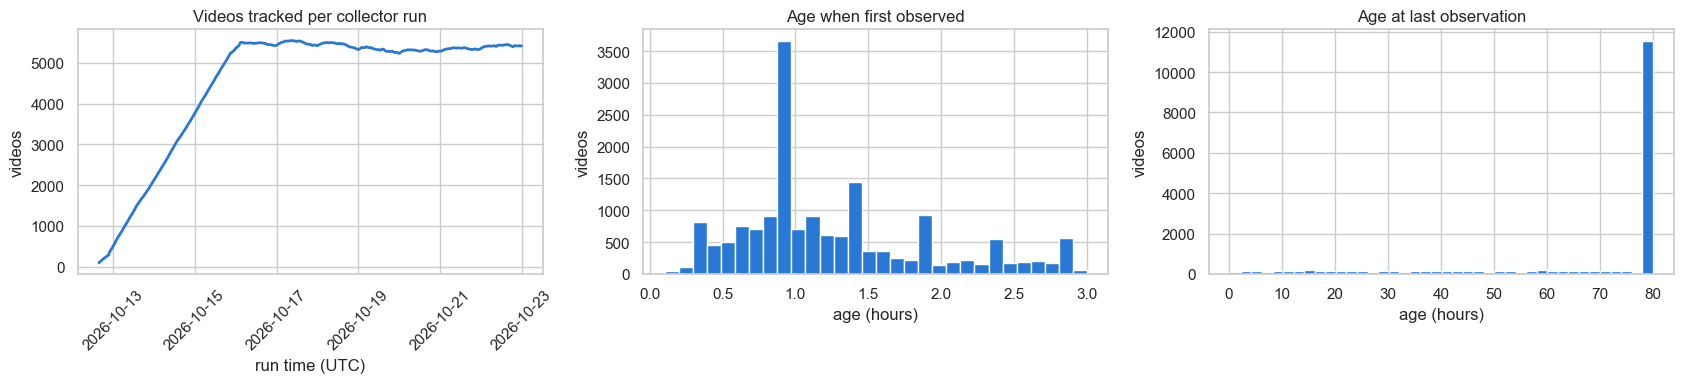

In [34]:
snapshot_manifest["interval_hours"] = snapshot_manifest["started_at"].diff().dt.total_seconds() / 3600
snapshot_manifest["run_seconds"] = (snapshot_manifest["finished_at"] - snapshot_manifest["started_at"]).dt.total_seconds()
display(snapshot_manifest[["rows", "interval_hours", "run_seconds"]].describe().round(2))

irregular = snapshot_manifest.query("interval_hours > 1.5 or interval_hours < 0.5")
print("Runs whose gap from the previous run is not ≈1h:")
display(irregular[["snapshot_file", "started_at", "interval_hours"]].round(2))

videos["hours_since_publish_at_snapshot"] = (DATA_SNAPSHOT_AT - videos["published_at"]).dt.total_seconds() / 3600
coverage_rows = []
for hour, tol in [(6, 1), (24, 2), (48, 2), (72, 2), (80, 2)]:
    old_enough = videos.loc[videos["hours_since_publish_at_snapshot"] >= hour + tol, "video_id"]
    has_snapshot = old_enough.isin(snapshot_nearest(observations, hour, tol).index)
    coverage_rows.append({
        "age": f"{hour}h ± {tol}h",
        "videos old enough": len(old_enough),
        "with a snapshot": int(has_snapshot.sum()),
        "coverage %": round(100 * has_snapshot.mean(), 2),
    })
display(pd.DataFrame(coverage_rows))

coverage_by_video = observations.groupby("video_id")["age_hours"].agg(first_age="min", last_age="max")
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(snapshot_manifest["started_at"], snapshot_manifest["rows"], color=BAR_COLOR, lw=2)
axes[0].set(title="Videos tracked per collector run", xlabel="run time (UTC)", ylabel="videos")
axes[0].tick_params(axis="x", rotation=45)
axes[1].hist(coverage_by_video["first_age"], bins=30, color=BAR_COLOR, edgecolor="white")
axes[1].set(title="Age when first observed", xlabel="age (hours)", ylabel="videos")
axes[2].hist(coverage_by_video["last_age"], bins=40, color=BAR_COLOR, edgecolor="white")
axes[2].set(title="Age at last observation", xlabel="age (hours)", ylabel="videos")
plt.tight_layout()
plt.show()

### Counts that go down

YouTube sometimes removes invalid views or likes, and likes can disappear when a creator hides them. These decreases are flagged, not treated as collection errors. They matter for growth features, which assume counts only go up.

In [35]:
# observations is already sorted by video and time
decrease_rows = []
for metric in ["view_count", "like_count", "comment_count"]:
    previous = observations.groupby("video_id")[metric].shift()
    drop = (previous - observations[metric])[lambda d: d > 0]
    relative = drop / previous[drop.index]
    decrease_rows.append({
        "metric": metric,
        "decrease events": len(drop),
        "videos affected": observations.loc[drop.index, "video_id"].nunique(),
        "median drop": drop.median(),
        "max drop": drop.max(),
        "median drop % of previous": round(100 * relative.median(), 3),
        "max drop % of previous": round(100 * relative.max(), 1),
    })
    if metric == "like_count":
        top = drop.nlargest(5).index
        largest_like_drops = observations.loc[top, ["video_id", "observed_at", "age_hours", "like_count"]].assign(
            previous=previous[top], drop=drop[top])
    del previous
display(pd.DataFrame(decrease_rows))
print("Largest like-count drops:")
display(largest_like_drops)

,metric,decrease events,videos affected,median drop,max drop,median drop % of previous,max drop % of previous
0,view_count,25645,7326,7.0,13950.0,0.040,100.0
1,like_count,22334,8353,1.0,40311.0,0.253,100.0
2,comment_count,2048,1591,1.0,4278.0,2.439,100.0


Largest like-count drops:


,video_id,observed_at,age_hours,like_count,previous,drop
885355,liEg8aeyP0A,2026-10-16 20:53:37.998493+00:00,43.941,0.0,40311.0,40311.0
721377,cVfOEeOYr8U,2026-10-16 20:53:47.821845+00:00,23.887,0.0,31873.0,31873.0
736885,dLz9Lafvqm4,2026-10-16 20:53:38.438524+00:00,42.885,0.0,24219.0,24219.0
1032202,uNPASrx-Iqo,2026-10-15 19:53:29.892353+00:00,42.801,0.0,22849.0,22849.0
1107746,yvJwYhuLFlA,2026-10-16 20:53:28.181556+00:00,74.805,0.0,13337.0,13337.0


## Study population: US and Canadian channels

Country is the channel's **self-reported** `snippet.country`. It is not upload location or audience location, and about a quarter of channels leave it blank. Filtering to US and CA therefore selects creators who chose to state a North American country, which is a form of selection bias to state in the report.

In [36]:
countries_latest = countries.sort_values("country_checked_at").drop_duplicates("channel_id", keep="last")
# Keep videos unchanged so this cell can be rerun safely.
video_geo = videos.merge(
    countries_latest[["channel_id", "channel_country"]],
    on="channel_id", how="left", validate="many_to_one",
)
video_geo["country_group"] = video_geo["channel_country"].where(
    video_geo["channel_country"].isin(STUDY_COUNTRIES), "Other"
)
video_geo.loc[video_geo["channel_country"].isna(), "country_group"] = "Unknown"
video_geo["in_study"] = video_geo["channel_country"].isin(STUDY_COUNTRIES)

country_table = pd.DataFrame({
    "channels": channels.merge(countries_latest, on="channel_id", how="left")["channel_country"].fillna("Unknown").value_counts(),
    "videos": video_geo["channel_country"].fillna("Unknown").value_counts(),
}).sort_values("videos", ascending=False)
display(country_table.head(15))

study_videos = video_geo[video_geo["in_study"]].copy()
study_ids = set(study_videos["video_id"])
study_obs = observations[observations["video_id"].isin(study_ids)].copy()

display(study_videos.groupby("channel_country").agg(videos=("video_id", "size"), channels=("channel_id", "nunique")))
print(f"study population: {len(study_ids):,} videos from {study_videos['channel_id'].nunique():,} channels, "
      f"{len(study_obs):,} observations")
print(f"unknown-country videos kept separate: {video_geo['channel_country'].isna().sum():,}")

,channels,videos
channel_country,,
IN,2959,4867
Unknown,2235,3477
US,983,1808
ID,761,1376
BR,569,1184
KR,196,444
VN,213,434
TR,170,417
BD,181,325


,videos,channels
channel_country,,
CA,61,32
US,1808,983


study population: 1,869 videos from 1,015 channels, 122,955 observations
unknown-country videos kept separate: 3,477


## Which prediction experiments does the data support?

For each candidate experiment, count videos that have both a feature snapshot (the latest one in the hour before the cutoff, so no look-ahead) and an outcome snapshot (within ±2h). Narrowing the outcome tolerance to ±1h changes these counts by under 1%. The feature window must stay a full hour because snapshots are taken hourly. The last two columns show how many viral examples the study population would give at a 10% positive rate, and roughly how many would land in a 20% test split. Fewer than about 50 test positives makes model comparisons noisy.

In [37]:
EXPERIMENTS = [(6, 24), (6, 48), (6, 72), (24, 72)]
rows = []
for feature_hour, outcome_hour in EXPERIMENTS:
    both = snapshot_as_of(observations, feature_hour, EARLY_WINDOW).index.intersection(
        snapshot_nearest(observations, outcome_hour, OUTCOME_TOL).index)
    n_study = int(both.isin(study_ids).sum())
    rows.append({
        "experiment": f"{feature_hour}h → {outcome_hour}h",
        "all countries": len(both),
        "US+CA": n_study,
        "US+CA positives (10%)": round(0.10 * n_study),
        "≈ positives in 20% test": round(0.02 * n_study),
    })
display(pd.DataFrame(rows))
print(f"Data snapshot: {DATA_SNAPSHOT_AT:%Y-%m-%d %H:%M} UTC")

,experiment,all countries,US+CA,US+CA positives (10%),≈ positives in 20% test
0,6h → 24h,15345,1703,170,34
1,6h → 48h,13641,1523,152,30
2,6h → 72h,11989,1341,134,27
3,24h → 72h,12062,1348,135,27


Data snapshot: 2026-10-22 23:53 UTC


## Do 24h, 48h, 72h and 80h outcomes rank videos the same way?

This supports the choice of the 72h horizon. If rankings barely change after 24h, a later horizon adds little new information. It also shows how much of a video's 72h audience has already arrived by 24h and 48h.

In [38]:
HORIZONS = [24, 48, 72, 80]
horizon_panel = pd.concat(
    [snapshot_nearest(study_obs, h, OUTCOME_TOL)["view_count"].rename(f"views_{h}h") for h in HORIZONS], axis=1
)
display(horizon_panel.notna().sum().rename("US+CA videos with outcome").to_frame())
print("Spearman rank correlation between horizons:")
display(horizon_panel.corr(method="spearman").round(3))

def compare_top_deciles(panel, earlier, later):
    common = panel[[f"views_{earlier}h", f"views_{later}h"]].dropna()
    top_earlier = common.iloc[:, 0] >= common.iloc[:, 0].quantile(VIRAL_QUANTILE)
    top_later = common.iloc[:, 1] >= common.iloc[:, 1].quantile(VIRAL_QUANTILE)
    return {
        "comparison": f"{earlier}h → {later}h",
        "videos": len(common),
        "top-10% at earlier age still top-10% later (%)": round(100 * (top_earlier & top_later).sum() / top_earlier.sum(), 1),
        "label agreement (%)": round(100 * top_earlier.eq(top_later).mean(), 1),
    }

display(pd.DataFrame([compare_top_deciles(horizon_panel, a, b) for a, b in [(24, 48), (48, 72), (24, 72), (72, 80)]]))

share = horizon_panel.dropna(subset=["views_24h", "views_48h", "views_72h"]).query("views_72h > 0")
print("Share of 72h views already reached (quartiles across videos):")
display(pd.DataFrame({
    "by 24h": share["views_24h"] / share["views_72h"],
    "by 48h": share["views_48h"] / share["views_72h"],
}).quantile([0.25, 0.5, 0.75]).round(3))

,US+CA videos with outcome
views_24h,1712
views_48h,1531
views_72h,1349
views_80h,1264


Spearman rank correlation between horizons:


,views_24h,views_48h,views_72h,views_80h
views_24h,1.000,0.986,0.974,0.971
views_48h,0.986,1.000,0.997,0.995
views_72h,0.974,0.997,1.000,1.000
views_80h,0.971,0.995,1.000,1.000


,comparison,videos,top-10% at earlier age still top-10% later (%),label agreement (%)
0,24h → 48h,1531,92.9,98.6
1,48h → 72h,1349,94.1,98.8
2,24h → 72h,1349,87.4,97.5
3,72h → 80h,1264,98.4,99.7


Share of 72h views already reached (quartiles across videos):


,by 24h,by 48h
0.25,0.555,0.836
0.50,0.707,0.909
0.75,0.822,0.954


## Outcome: views at 72 hours

**Viral = 72h views at or above the 90th percentile of the US+CA study population.** This measures popularity, not network spread. The threshold here is computed on all eligible videos for exploration only. For modeling, it must be estimated on the training split alone to avoid test-set leakage.

US+CA videos with a 72h outcome: 1,349
exploratory viral threshold (90th percentile): 955,886 views
videos labeled viral: 135


,views_72h
0.00,280.00
0.25,35230.00
0.50,95813.00
0.75,311212.00
0.90,955886.20
0.95,1813622.20
0.99,5295156.28
1.00,17343709.00


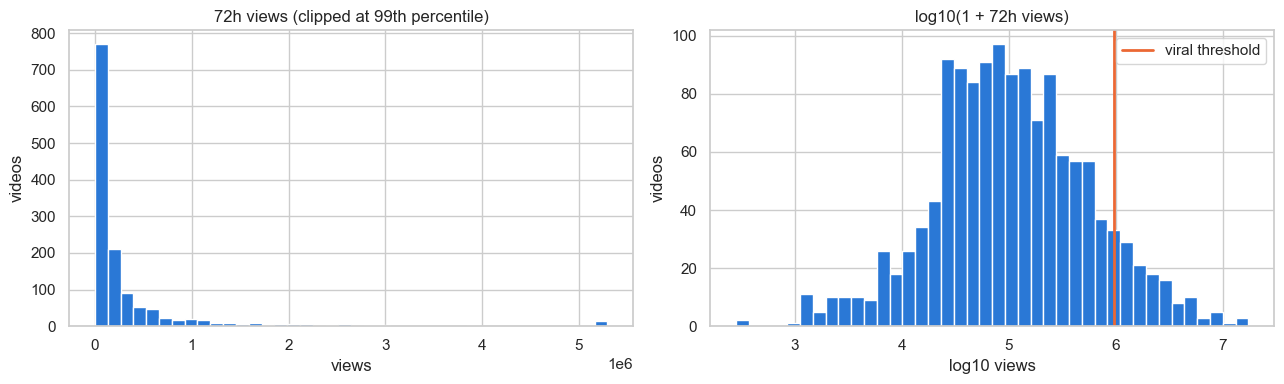

In [39]:
outcome = snapshot_nearest(study_obs, OUTCOME_HOURS, OUTCOME_TOL)
VIRAL_THRESHOLD = outcome["view_count"].quantile(VIRAL_QUANTILE)
print(f"US+CA videos with a {OUTCOME_HOURS}h outcome: {len(outcome):,}")
print(f"exploratory viral threshold (90th percentile): {VIRAL_THRESHOLD:,.0f} views")
print(f"videos labeled viral: {(outcome['view_count'] >= VIRAL_THRESHOLD).sum():,}")
display(outcome["view_count"].quantile([0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1]).rename(f"views_{OUTCOME_HOURS}h").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
clip = outcome["view_count"].quantile(0.99)
axes[0].hist(outcome["view_count"].clip(upper=clip), bins=40, color=BAR_COLOR, edgecolor="white")
axes[0].set(title=f"{OUTCOME_HOURS}h views (clipped at 99th percentile)", xlabel="views", ylabel="videos")
axes[1].hist(np.log10(outcome["view_count"] + 1), bins=40, color=BAR_COLOR, edgecolor="white")
axes[1].axvline(np.log10(VIRAL_THRESHOLD + 1), color=VIRAL_COLOR, lw=2, label="viral threshold")
axes[1].set(title=f"log10(1 + {OUTCOME_HOURS}h views)", xlabel="log10 views", ylabel="videos")
axes[1].legend()
plt.tight_layout()
plt.show()

## Build the one-row analysis table

One row per US+CA video with a 72h outcome. This is an EDA table, not the final model matrix. Column groups:
- **Upload-time:** duration, publish time, title/description/tag features, Emily's title-style features.
- **Channel** (known at first sighting): subscribers, total views, video count, channel age.
- **Early engagement** (as of 1h, 3h, 6h; no look-ahead): views, likes, comments, rates, growth since first observation.
- **Outcome and label:** `views_72h` and `viral`. These must never be used as features.

Title-style features are computed on the title with hashtags removed. Nearly every collected title contains `#shorts`, because that is the search query the collector uses.

In [40]:
TARGET = f"views_{OUTCOME_HOURS}h"

def as_of_features(obs, hour, window=EARLY_WINDOW):
    snap = snapshot_as_of(obs, hour, window)
    return snap[["age_hours", "view_count", "like_count", "comment_count"]].rename(columns={
        "age_hours": f"age_{hour}h", "view_count": f"views_{hour}h",
        "like_count": f"likes_{hour}h", "comment_count": f"comments_{hour}h",
    })

first_obs = (
    study_obs.dropna(subset=["view_count"]).sort_values(["video_id", "age_hours"])
    .drop_duplicates("video_id").set_index("video_id")[["age_hours", "view_count"]]
    .rename(columns={"age_hours": "first_obs_age", "view_count": "views_first_obs"})
)
outcome_cols = outcome[["view_count"]].rename(columns={"view_count": TARGET})

df = (
    study_videos.set_index("video_id")
    .join(outcome_cols, how="inner")
    .join(first_obs)
    .join([as_of_features(study_obs, h) for h in EARLY_HOURS])
    .reset_index()
    .merge(channels.drop(columns=["channel_title", "first_seen_at"]), on="channel_id", how="left", validate="many_to_one")
)

# Outcome and labels
df["log_target"] = np.log10(df[TARGET] + 1)
df["viral"] = df[TARGET] >= VIRAL_THRESHOLD

# Upload-time features. US+CA spans several time zones; US Eastern is a reference clock, not each creator's local time.
df["published_et"] = df["published_at"].dt.tz_convert("America/New_York")
df["pub_hour_et"] = df["published_et"].dt.hour
df["pub_dow_et"] = df["published_et"].dt.day_name()
df["pub_date_et"] = df["published_et"].dt.date

titles = df["title"].fillna("")
title_text = titles.str.replace(r"#\w+", " ", regex=True)   # title without hashtags
EMOJI_PATTERN = "[\U0001F1E6-\U0001F1FF\U0001F300-\U0001FAFF☀-➿⬀-⯿]"
df["title_len"] = titles.str.len()
df["title_word_count"] = title_text.str.split().str.len()
df["title_hashtags_n"] = titles.str.count(r"#\w+")
df["description_len"] = df["description"].fillna("").str.len()
df["n_tags"] = df["tags"].map(parse_json_list).map(len)
df["n_hashtags"] = (titles + " " + df["description"].fillna("")).str.count(r"#\w+")
df["non_latin_letters"] = title_text.map(
    lambda text: any(c.isalpha() and not unicodedata.name(c, "").startswith("LATIN") for c in text)
)

# Emily's title-style features (on the hashtag-free title)
cased_letters = title_text.map(lambda t: [c for c in t if c.isupper() or c.islower()])
df["uppercase_ratio"] = cased_letters.map(lambda cs: sum(c.isupper() for c in cs) / len(cs) if cs else 0.0)
df["is_all_caps"] = cased_letters.map(lambda cs: len(cs) >= 3 and all(c.isupper() for c in cs))
df["has_exclamation"] = title_text.str.contains("!", regex=False)
df["has_question"] = title_text.str.contains("?", regex=False)
df["has_ellipsis"] = title_text.str.contains(r"\.\.\.|…", regex=True)
df["repeated_punctuation"] = title_text.str.contains(r"[!?]{2,}", regex=True)
df["emoji_count"] = titles.str.count(EMOJI_PATTERN)
df["has_emoji"] = df["emoji_count"] > 0
df["has_number"] = title_text.str.contains(r"\d", regex=True)

# Channel features (as of first sighting)
df["channel_age_days"] = (df["published_at"] - df["channel_created_at"]).dt.total_seconds() / 86400
df["channel_avg_views"] = df["total_channel_views"] / df["total_channel_videos"].clip(lower=1)

# Early-engagement features at the 6-hour cutoff
v6 = df["views_6h"]
df["like_rate_6h"] = df["likes_6h"] / v6.replace(0, np.nan)
df["comment_rate_6h"] = df["comments_6h"] / v6.replace(0, np.nan)
hours_first_to_6h = df["age_6h"] - df["first_obs_age"]
enough_gap = hours_first_to_6h >= 1
df["views_per_hour_first_to_6h"] = ((v6 - df["views_first_obs"]) / hours_first_to_6h).where(enough_gap)
df["log_growth_first_to_6h"] = (np.log1p(v6) - np.log1p(df["views_first_obs"])).where(enough_gap)

print(f"{len(df):,} US+CA videos in the analysis table; {df['viral'].sum():,} labeled viral")
print(f"viral threshold: {VIRAL_THRESHOLD:,.0f} views at {OUTCOME_HOURS}h (median {df[TARGET].median():,.0f})")

1,349 US+CA videos in the analysis table; 135 labeled viral
viral threshold: 955,886 views at 72h (median 95,813)


## Missingness in the analysis table

`views_1h` is often missing because many videos had not been discovered yet. Discovery may also depend on search ranking, so this missingness should not automatically be treated as random. Prefer 6h features, retain missingness indicators, or measure growth from each video's first observation.

In [41]:
missing_cols = ["views_1h", "views_3h", "views_6h", "likes_6h", "comments_6h", "views_per_hour_first_to_6h",
                "description", "channel_created_at", "subscriber_count", "duration_seconds", "title_len"]
missing_table = pd.DataFrame({
    "missing": df[missing_cols].isna().sum(),
    "percent": df[missing_cols].isna().mean().mul(100).round(1),
}).sort_values("missing", ascending=False)
missing_by_label = (
    df[missing_cols].isna().groupby(df["viral"]).mean().mul(100).round(1).T
    .rename(columns={False: "% missing (non-viral)", True: "% missing (viral)"})
)
display(missing_table.join(missing_by_label))
print("Age at first observation (hours):")
display(df["first_obs_age"].describe().round(2).to_frame().T)

,missing,percent,% missing (non-viral),% missing (viral)
views_1h,802,59.5,61.8,38.5
description,541,40.1,40.0,40.7
likes_6h,90,6.7,6.8,5.9
comments_6h,25,1.9,1.6,3.7
views_3h,16,1.2,1.2,0.7
views_6h,8,0.6,0.5,1.5
views_per_hour_first_to_6h,8,0.6,0.5,1.5
channel_created_at,0,0.0,0.0,0.0
subscriber_count,0,0.0,0.0,0.0
duration_seconds,0,0.0,0.0,0.0


Age at first observation (hours):


,count,mean,std,min,25%,50%,75%,max
first_obs_age,1349.0,1.47,0.76,0.18,0.89,1.22,1.92,2.97


## Creator size

Does the label mostly reflect channels that were already large? Channel statistics were recorded when each channel first entered the dataset.

,Spearman with views_72h
subscriber_count,0.232
total_channel_views,0.297
total_channel_videos,-0.139
channel_avg_views,0.568


,videos,median_subscribers,median_views,viral_rate_pct
subscriber_decile,,,,
1,135,4200.0,36735.0,3.7
2,135,25600.0,80369.0,5.9
3,135,62900.0,68309.0,6.7
4,135,116000.0,100340.0,8.9
5,135,175000.0,131305.0,9.6
6,134,335500.0,59411.0,11.2
7,135,728000.0,133399.0,14.1
8,135,1490000.0,145731.0,14.1
9,135,3560000.0,107620.0,11.9


channels in the analysis table: 812; with 2+ videos: 220
share of videos from the 10 largest contributors: 10.9%


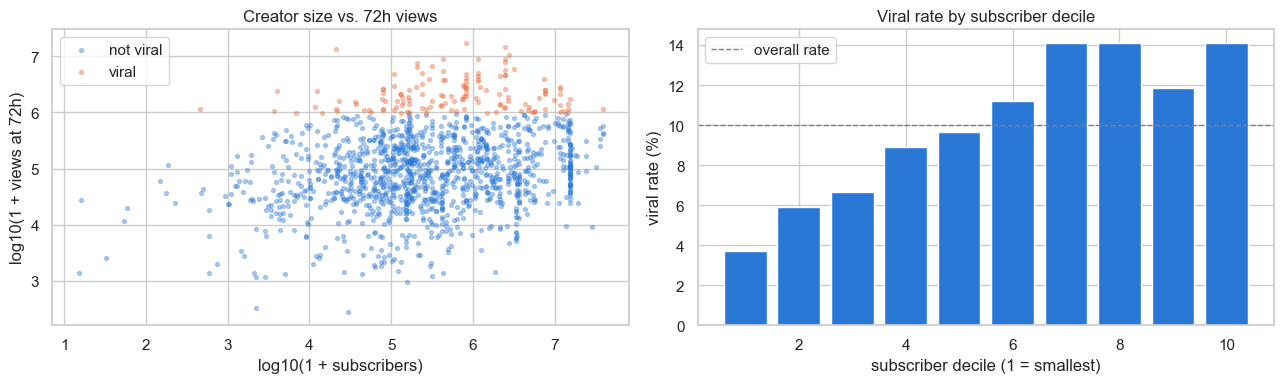

In [42]:
display(df[[TARGET, "subscriber_count", "total_channel_views", "total_channel_videos", "channel_avg_views"]]
        .corr(method="spearman")[TARGET].drop(TARGET).rename(f"Spearman with {TARGET}").round(3).to_frame())

df["subscriber_decile"] = pd.qcut(df["subscriber_count"].rank(method="first"), 10, labels=False) + 1
subscriber_deciles = df.groupby("subscriber_decile").agg(
    videos=("video_id", "size"),
    median_subscribers=("subscriber_count", "median"),
    median_views=(TARGET, "median"),
    viral_rate_pct=("viral", "mean"),
)
subscriber_deciles["viral_rate_pct"] *= 100
display(subscriber_deciles.round(1))

videos_per_channel = df.groupby("channel_id")["video_id"].size().sort_values(ascending=False)
print(f"channels in the analysis table: {len(videos_per_channel):,}; with 2+ videos: {(videos_per_channel > 1).sum():,}")
print(f"share of videos from the 10 largest contributors: {videos_per_channel.head(10).sum() / len(df):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for is_viral in [False, True]:
    part = df[df["viral"] == is_viral]
    axes[0].scatter(np.log10(part["subscriber_count"] + 1), part["log_target"], s=8, alpha=0.35,
                    color=LABEL_PALETTE[is_viral], label="viral" if is_viral else "not viral")
axes[0].set(title="Creator size vs. 72h views", xlabel="log10(1 + subscribers)", ylabel="log10(1 + views at 72h)")
axes[0].legend()
axes[1].bar(subscriber_deciles.index, subscriber_deciles["viral_rate_pct"], color=BAR_COLOR)
axes[1].axhline(100 * (1 - VIRAL_QUANTILE), color="gray", ls="--", lw=1, label="overall rate")
axes[1].set(title="Viral rate by subscriber decile", xlabel="subscriber decile (1 = smallest)", ylabel="viral rate (%)")
axes[1].legend()
plt.tight_layout()
plt.show()

## Correlation heatmap

Spearman (rank) correlation, which is robust to the heavy tails. It is computed across **all** videos rather than within the viral and non-viral groups separately. Splitting on the outcome first restricts each group's range and distorts the correlations. Look for features that track the target, and for near-duplicate features (redundancy).

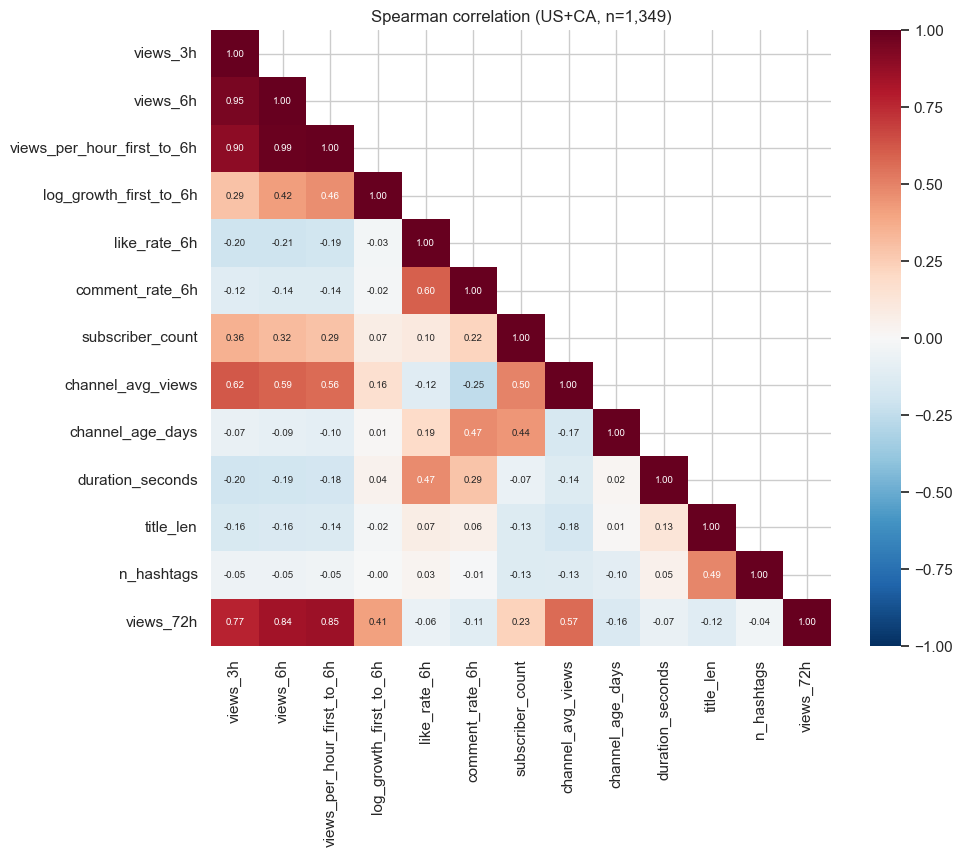

,Spearman with views_72h
views_per_hour_first_to_6h,0.852
views_6h,0.843
views_3h,0.769
channel_avg_views,0.568
log_growth_first_to_6h,0.413
subscriber_count,0.232
channel_age_days,-0.155
title_len,-0.121
comment_rate_6h,-0.115
duration_seconds,-0.071


In [43]:
corr_cols = [
    "views_3h", "views_6h", "views_per_hour_first_to_6h", "log_growth_first_to_6h",
    "like_rate_6h", "comment_rate_6h",
    "subscriber_count", "channel_avg_views", "channel_age_days",
    "duration_seconds", "title_len", "n_hashtags", TARGET,
]
corr = df[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title(f"Spearman correlation (US+CA, n={len(df):,})")
plt.show()

corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).rename(f"Spearman with {TARGET}").to_frame()

## How well do early views predict 72h views?

The 3h and 6h cutoffs are compared on the **same videos** (those with both snapshots, which is nearly all of them), so any improvement comes from waiting longer, not from a different sample. The 1h row uses only the videos already discovered at 1h. About 60% were not, and early-discovered videos are more often viral, so that row's higher viral rate makes it look better than it is.

- **ROC-AUC:** how well early views rank viral above non-viral videos (0.5 is random, 1.0 is perfect).
- **PR-AUC:** reported because only about 10% of videos are viral; its random baseline is the viral rate.
- **Precision / recall:** for a simple rule that flags the top 10% by early views. The 6h row is the **baseline a model must beat**.

With about 130 viral videos, AUC differences of a few hundredths are within noise.

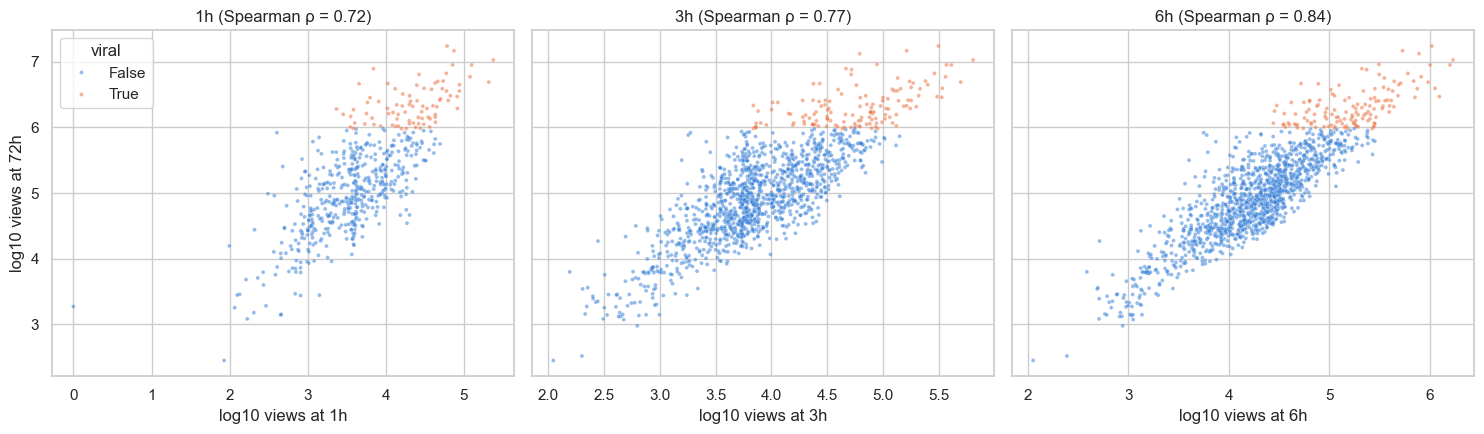

,cutoff,videos,viral rate,Spearman ρ,ROC-AUC,PR-AUC,precision (top-10% flag),recall (top-10% flag)
0,1h,544,0.153,0.724,0.887,0.685,0.745,0.494
1,3h,1329,0.099,0.769,0.918,0.680,0.609,0.614
2,6h,1329,0.099,0.843,0.949,0.748,0.639,0.644


In [44]:
# 3h and 6h share one cohort; 1h is limited to videos already discovered at 1h (see note above).
auc_cohort = df.dropna(subset=["views_3h", "views_6h"])

fig, axes = plt.subplots(1, len(EARLY_HOURS), figsize=(15, 4.5), sharey=True)
baseline_rows = []
for ax, h in zip(axes, EARLY_HOURS):
    d = auc_cohort.dropna(subset=[f"views_{h}h"])
    scores = d[f"views_{h}h"]
    sns.scatterplot(x=np.log10(scores + 1), y=d["log_target"], hue=d["viral"], s=8, alpha=0.5,
                    ax=ax, palette=LABEL_PALETTE, legend=(h == EARLY_HOURS[0]))
    rho = scores.corr(d[TARGET], method="spearman")
    ax.set(xlabel=f"log10 views at {h}h", ylabel=f"log10 views at {OUTCOME_HOURS}h", title=f"{h}h (Spearman ρ = {rho:.2f})")
    flagged = scores >= scores.quantile(VIRAL_QUANTILE)
    baseline_rows.append({
        "cutoff": f"{h}h",
        "videos": len(d),
        "viral rate": round(d["viral"].mean(), 3),
        "Spearman ρ": round(rho, 3),
        "ROC-AUC": round(roc_auc_score(d["viral"], scores), 3),
        "PR-AUC": round(average_precision_score(d["viral"], scores), 3),
        "precision (top-10% flag)": round((flagged & d["viral"]).sum() / flagged.sum(), 3),
        "recall (top-10% flag)": round((flagged & d["viral"]).sum() / d["viral"].sum(), 3),
    })
plt.tight_layout()
plt.show()
display(pd.DataFrame(baseline_rows))

## Growth over time: top 10% vs. bottom 90%

Every snapshot of each video gets the video's label, so the two groups can be followed over time. Lines are medians by hour of age, with the interquartile range shaded. Velocity is views per hour since the previous snapshot; it is not computed over gaps shorter than 30 minutes, because counts that close together are noisy.

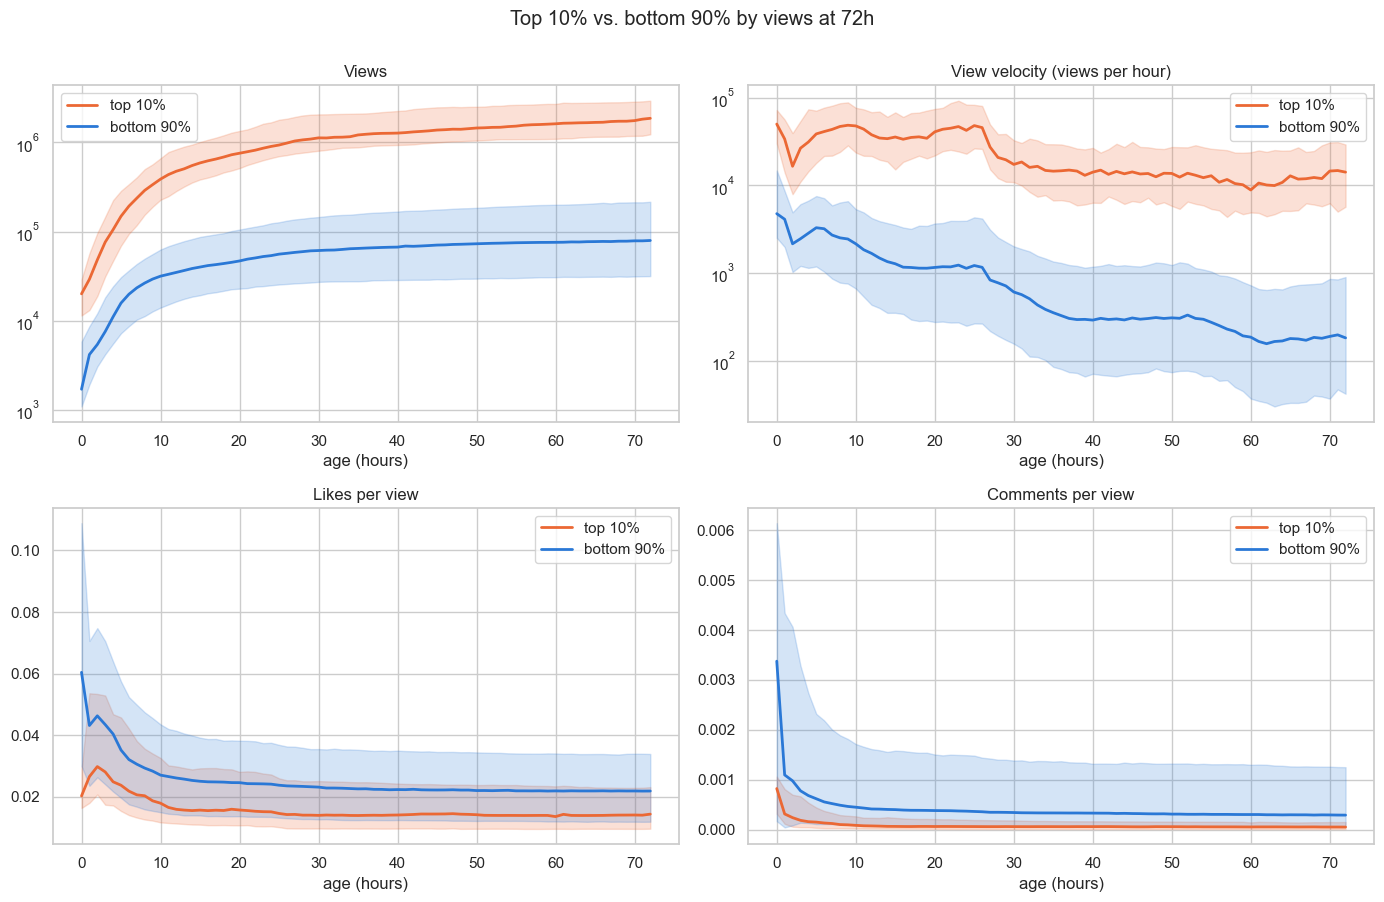

In [45]:
traj = (
    study_obs.dropna(subset=["view_count"])
    .merge(df[["video_id", "viral", TARGET]], on="video_id")
    .sort_values(["video_id", "age_hours"])
)
traj["group"] = np.where(traj["viral"], "top 10%", "bottom 90%")
gap = traj.groupby("video_id")["age_hours"].diff()
traj["velocity"] = (traj.groupby("video_id")["view_count"].diff() / gap).where(gap >= 0.5)
first_snapshot = gap.isna()
traj.loc[first_snapshot, "velocity"] = traj.loc[first_snapshot, "view_count"] / traj.loc[first_snapshot, "age_hours"]
traj["velocity"] = traj["velocity"].clip(lower=0)
traj["like_rate"] = traj["like_count"] / traj["view_count"].replace(0, np.nan)
traj["comment_rate"] = traj["comment_count"] / traj["view_count"].replace(0, np.nan)
traj["share_of_target"] = traj["view_count"] / traj[TARGET].replace(0, np.nan)
traj["age_bin"] = traj["age_hours"].round()
traj = traj[traj["age_bin"] <= OUTCOME_HOURS]

def plot_bands(ax, col, log=True):
    q = traj.groupby(["group", "age_bin"])[col].quantile([0.25, 0.5, 0.75]).unstack()
    for group, color in GROUP_COLORS.items():
        s = q.loc[group]
        ax.plot(s.index, s[0.5], color=color, lw=2, label=group)
        ax.fill_between(s.index, s[0.25], s[0.75], color=color, alpha=0.2)
    ax.set(xlabel="age (hours)", yscale="log" if log else "linear")
    ax.legend()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (col, title, log) in zip(axes.flat, [
    ("view_count", "Views", True),
    ("velocity", "View velocity (views per hour)", True),
    ("like_rate", "Likes per view", False),
    ("comment_rate", "Comments per view", False),
]):
    plot_bands(ax, col, log)
    ax.set_title(title)
fig.suptitle(f"Top 10% vs. bottom 90% by views at {OUTCOME_HOURS}h", y=1.0)
plt.tight_layout()
plt.show()

### How front-loaded is each group?

Each video's views as a fraction of its own 72h views. A curve that reaches 1 quickly means the video got most of its views early and then stalled; a slow climb means it kept growing.

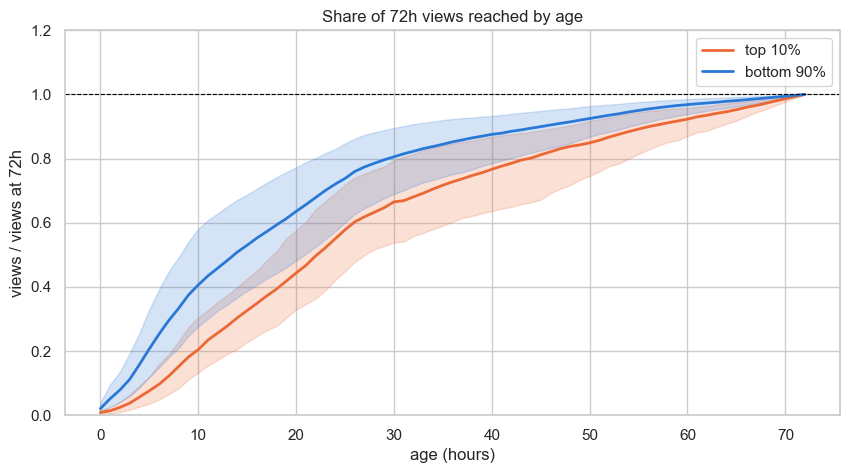

,age (h),"median views, top 10%","median views, bottom 90%","share of 72h views, top 10%","share of 72h views, bottom 90%"
0,1,29091.0,4158.0,0.014,0.052
1,3,76058.5,7533.0,0.038,0.112
2,6,192647.5,19772.0,0.097,0.253
3,12,475021.0,34766.0,0.256,0.459
4,24,901793.0,53631.0,0.550,0.720
5,48,1405024.5,71931.0,0.838,0.914


In [46]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_bands(ax, "share_of_target", log=False)
ax.axhline(1, color="black", lw=0.8, ls="--")
ax.set(ylabel=f"views / views at {OUTCOME_HOURS}h", title=f"Share of {OUTCOME_HOURS}h views reached by age", ylim=(0, 1.2))
plt.show()

checkpoint_rows = []
for h in [1, 3, 6, 12, 24, 48]:
    at_h = traj[traj["age_bin"] == h].groupby("group")
    medians, shares = at_h["view_count"].median(), at_h["share_of_target"].median()
    checkpoint_rows.append({
        "age (h)": h,
        "median views, top 10%": medians.get("top 10%"),
        "median views, bottom 90%": medians.get("bottom 90%"),
        "share of 72h views, top 10%": round(shares.get("top 10%"), 3),
        "share of 72h views, bottom 90%": round(shares.get("bottom 90%"), 3),
    })
display(pd.DataFrame(checkpoint_rows))

## Content: duration and title style

The title-style comparison is descriptive: it reports prevalence and percentage-point differences. Videos from the same channel are not independent, so these are associations rather than formal statistical tests.

titles containing '#shorts' (any case): 99.9%
titles containing any hashtag:         99.9%


,videos,median_views,viral_rate_pct
duration_bin,,,
"(-0.001, 15.0]",108,157634.5,14.8
"(15.0, 30.0]",356,96622.5,11.5
"(30.0, 60.0]",555,90444.0,9.5
"(60.0, 90.0]",174,74756.5,5.7
"(90.0, 120.0]",71,63920.0,7.0
"(120.0, 180.0]",85,188232.0,11.8


viral,non-viral %,viral %,difference (pts)
All-caps title,7.6,3.7,-3.9
Exclamation mark,19.5,10.4,-9.2
Question mark,12.8,8.1,-4.6
Ellipsis,5.0,8.9,3.9
Repeated !/?,4.3,0.7,-3.5
Emoji,40.9,43.0,2.1
Contains a number,11.0,14.8,3.8
Non-Latin letters,8.2,20.7,12.5


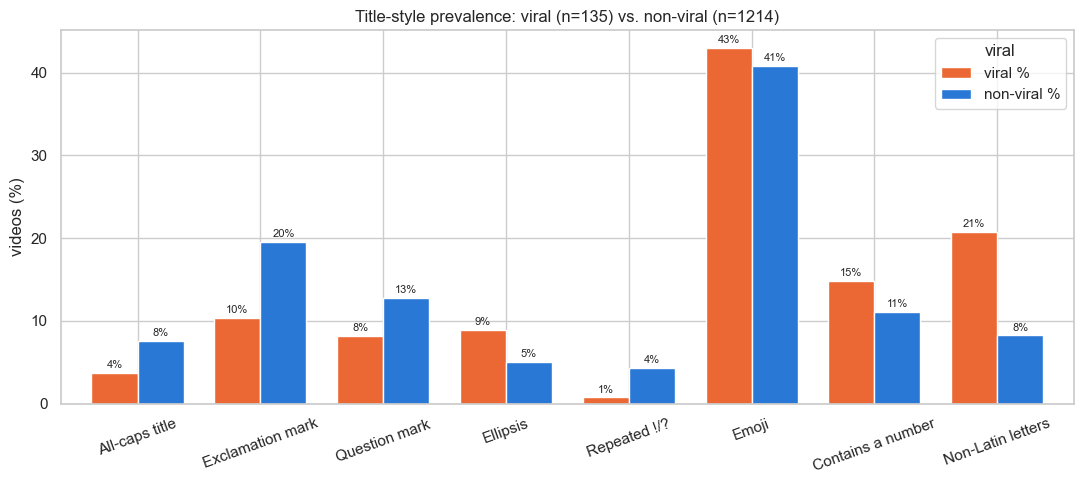

,duration_seconds,title_len,title_word_count,uppercase_ratio,emoji_count,title_hashtags_n,description_len,n_tags,n_hashtags
viral,,,,,,,,,
non-viral,42.0,59.0,7.0,0.18,0.0,2.0,64.5,0.0,4.0
viral,36.0,51.0,6.0,0.13,0.0,3.0,65.0,0.0,3.0


In [47]:
print(f"titles containing '#shorts' (any case): {titles.str.contains('#shorts', case=False).mean():.1%}")
print(f"titles containing any hashtag:         {titles.str.contains('#', regex=False).mean():.1%}")

df["duration_bin"] = pd.cut(df["duration_seconds"], [0, 15, 30, 60, 90, 120, 180], include_lowest=True)
duration_summary = df.groupby("duration_bin", observed=True).agg(
    videos=("video_id", "size"), median_views=(TARGET, "median"), viral_rate_pct=("viral", "mean"))
duration_summary["viral_rate_pct"] *= 100
display(duration_summary.round(1))

style_features = {
    "All-caps title": "is_all_caps", "Exclamation mark": "has_exclamation", "Question mark": "has_question",
    "Ellipsis": "has_ellipsis", "Repeated !/?": "repeated_punctuation", "Emoji": "has_emoji",
    "Contains a number": "has_number", "Non-Latin letters": "non_latin_letters",
}
n_viral, n_nonviral = df["viral"].sum(), (~df["viral"]).sum()
style_table = (
    df.groupby("viral")[list(style_features.values())].mean().T.mul(100)
    .rename(index={value: label for label, value in style_features.items()})
    .rename(columns={False: "non-viral %", True: "viral %"})
)
style_table["difference (pts)"] = style_table["viral %"] - style_table["non-viral %"]
display(style_table.round(1))

ax = style_table[["viral %", "non-viral %"]].plot(kind="bar", figsize=(11, 5), width=0.75,
                                                  color=[VIRAL_COLOR, NONVIRAL_COLOR])
ax.set(ylabel="videos (%)", xlabel="", title=f"Title-style prevalence: viral (n={n_viral}) vs. non-viral (n={n_nonviral})")
ax.tick_params(axis="x", rotation=20)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

numeric_content = ["duration_seconds", "title_len", "title_word_count", "uppercase_ratio", "emoji_count",
                   "title_hashtags_n", "description_len", "n_tags", "n_hashtags"]
display(df.groupby("viral")[numeric_content].median().rename(index={False: "non-viral", True: "viral"}).round(2))

## Text: tags, description hashtags, and title words

Each term is counted at most once per video, then compared between viral (top 10%) and non-viral videos. Three term types are covered:
- **tags** (lowercased, `#` removed, multi-hashtag strings split);
- **description hashtags**;
- **title words** (hashtags, numbers, single letters, and English stop words removed).

Caveats:
- Many videos have no tags or description hashtags, so those counts come from a minority of videos.
- One channel can reuse the same terms on many videos, so results are limited to terms used by at least three channels.
- Thousands of terms are compared with no correction for multiple comparisons. Treat these lists as leads, not evidence.

In [48]:
HASHTAG_RE = re.compile(r"#(\w+)")
WORD_RE = re.compile(r"[^\W\d_]{2,}")
STOP_WORDS = set(ENGLISH_STOP_WORDS) | {"don", "didn", "doesn", "isn", "wasn", "won", "ll", "ve", "re"}
MIN_TERM_CHANNELS = 3

def clean_tags(raw):
    """Return unique, normalized tags; split only strings holding several hashtags ("#a #b")."""
    tags = set()
    for tag in map(str, parse_json_list(raw)):
        parts = tag.split() if tag.count("#") > 1 else [tag]
        tags.update(p.strip().lstrip("#").strip().lower() for p in parts)
    return sorted(tags - {""})

def extract_hashtags(text):
    """Return unique hashtags from a text field."""
    return sorted(set(HASHTAG_RE.findall(str(text).lower()))) if pd.notna(text) else []

def extract_title_words(text):
    """Return unique informative words from a title."""
    if pd.isna(text):
        return []
    clean = HASHTAG_RE.sub(" ", str(text).lower())
    return sorted({word for word in WORD_RE.findall(clean) if word not in STOP_WORDS})

def summarize_terms(term_lists):
    """Compare term prevalence between viral and non-viral videos."""
    long = (
        df[["video_id", "channel_id", "viral"]]
        .assign(term=term_lists)
        .explode("term")
        .dropna(subset=["term"])
    )
    counts = (
        long.groupby(["term", "viral"])
        .agg(videos=("video_id", "nunique"), channels=("channel_id", "nunique"))
        .unstack("viral", fill_value=0)
    )
    counts.columns = [f"{'viral' if flag else 'nonviral'}_{metric}" for metric, flag in counts.columns]

    group_sizes = df["viral"].value_counts()
    counts["channels"] = long.groupby("term")["channel_id"].nunique()
    counts["viral_pct"] = 100 * counts["viral_videos"] / group_sizes[True]
    counts["nonviral_pct"] = 100 * counts["nonviral_videos"] / group_sizes[False]
    counts["difference_pts"] = counts["viral_pct"] - counts["nonviral_pct"]
    return counts.sort_values("difference_pts", ascending=False)

def show_term_summary(name, term_lists, n=8):
    """Display coverage plus the largest descriptive prevalence differences."""
    coverage = term_lists.str.len().gt(0).groupby(df["viral"]).mean().mul(100)
    print(f"{name}: coverage in non-viral={coverage.get(False, np.nan):.1f}%, viral={coverage.get(True, np.nan):.1f}%")

    summary = summarize_terms(term_lists)
    eligible = summary.query("channels >= @MIN_TERM_CHANNELS")
    columns = ["viral_pct", "nonviral_pct", "difference_pts", "channels"]
    extremes = pd.concat([eligible.head(n), eligible.tail(n)]).drop_duplicates()
    display(extremes.loc[:, columns].round(2))
    return summary

df["tag_list"] = df["tags"].map(clean_tags)
df["desc_hashtags"] = df["description"].map(extract_hashtags)
df["title_words"] = df["title"].map(extract_title_words)

tag_summary = show_term_summary("Tags", df["tag_list"])
hashtag_summary = show_term_summary("Description hashtags", df["desc_hashtags"])
title_word_summary = show_term_summary("Title words", df["title_words"])


Tags: coverage in non-viral=39.6%, viral=26.7%


,viral_pct,nonviral_pct,difference_pts,channels
term,,,,
trending,6.67,1.32,5.35,12
fyp,5.93,1.07,4.86,10
minecraft,6.67,2.47,4.20,18
kids,3.70,0.58,3.13,3
minecraft memes,2.22,0.16,2.06,3
minecraft shorts,2.96,1.07,1.89,10
memes,2.22,0.58,1.65,6
cute,1.48,0.16,1.32,3
funny,1.48,2.97,-1.48,29


Description hashtags: coverage in non-viral=45.9%, viral=34.1%


,viral_pct,nonviral_pct,difference_pts,channels
term,,,,
minecraft,7.41,2.88,4.52,25
fyp,3.70,1.15,2.55,14
funny,5.93,3.54,2.38,31
robloxanimation,2.22,0.25,1.98,4
animation,2.22,0.41,1.81,7
maizen,2.22,0.41,1.81,3
minecraftshorts,2.22,0.49,1.73,3
minecraftmemes,2.22,0.49,1.73,4
robloxedit,0.00,0.99,-0.99,6


Title words: coverage in non-viral=98.4%, viral=98.5%


,viral_pct,nonviral_pct,difference_pts,channels
term,,,,
baby,4.44,0.66,3.79,8
laugh,4.44,0.66,3.79,4
try,3.70,0.58,3.13,4
minecraft,4.44,1.57,2.88,18
vs,5.19,2.72,2.47,32
jj,2.96,0.58,2.39,6
wait,2.22,0.08,2.14,3
animation,2.96,0.82,2.14,6
gta,0.00,0.91,-0.91,6


## Publication timing

Times are on the **US Eastern** clock; US+CA creators span several time zones, so this is a reference clock, not each creator's local time. The data covers only about ten days, so each weekday appears on just one or two calendar dates, and day-of-week effects are tangled with what happened on those specific dates. Do not read them as stable weekday effects yet.

,videos,calendar_dates,median_views,viral_rate_pct
pub_dow_et,,,,
Monday,293,2,89231.0,9.9
Tuesday,173,1,95744.0,9.8
Wednesday,183,1,106001.0,15.8
Thursday,169,1,95214.0,7.7
Friday,175,1,115225.0,10.9
Saturday,171,1,93136.0,7.0
Sunday,185,1,93539.0,8.6


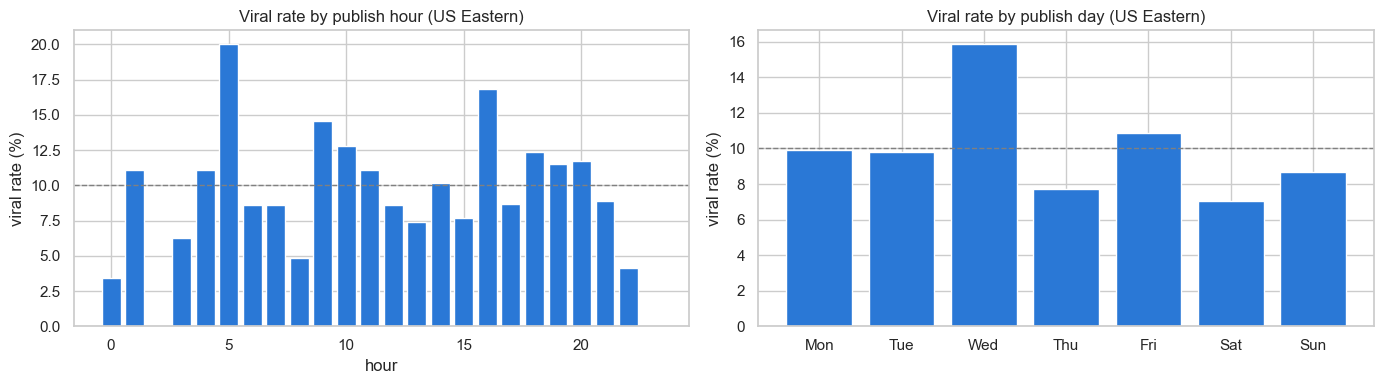

pub_hour_et,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
videos,29.0,18.0,19.0,16.0,27.0,20.0,35.0,35.0,41.0,48.0,47.0,54.0,70.0,81.0,108.0,130.0,119.0,104.0,97.0,87.0,68.0,45.0,24.0,27.0
viral_rate_pct,3.4,11.1,0.0,6.2,11.1,20.0,8.6,8.6,4.9,14.6,12.8,11.1,8.6,7.4,10.2,7.7,16.8,8.7,12.4,11.5,11.8,8.9,4.2,0.0


In [49]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
hour_summary = df.groupby("pub_hour_et").agg(videos=("video_id", "size"), viral_rate_pct=("viral", "mean"))
hour_summary["viral_rate_pct"] *= 100
day_summary = df.groupby("pub_dow_et").agg(
    videos=("video_id", "size"), calendar_dates=("pub_date_et", "nunique"),
    median_views=(TARGET, "median"), viral_rate_pct=("viral", "mean"),
).reindex(day_order)
day_summary["viral_rate_pct"] *= 100
display(day_summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(hour_summary.index, hour_summary["viral_rate_pct"], color=BAR_COLOR)
axes[0].set(title="Viral rate by publish hour (US Eastern)", xlabel="hour", ylabel="viral rate (%)")
axes[1].bar(day_summary.index.str[:3], day_summary["viral_rate_pct"], color=BAR_COLOR)
axes[1].set(title="Viral rate by publish day (US Eastern)", xlabel="", ylabel="viral rate (%)")
for ax in axes:
    ax.axhline(100 * (1 - VIRAL_QUANTILE), color="gray", ls="--", lw=1)
plt.tight_layout()
plt.show()
display(hour_summary.T.round(1))

## How does the study population compare with the rest of the data?

All countries, among videos with a 72h outcome. The last column applies the **US+CA** viral threshold to every group, to show whether other groups are more or less popular than the study population. This helps judge how far US+CA results might generalise.

In [50]:
outcome_all = snapshot_nearest(observations, OUTCOME_HOURS, OUTCOME_TOL)["view_count"].rename(TARGET)
comparison = (
    video_geo.set_index("video_id").join(outcome_all, how="inner").reset_index()
    .merge(channels[["channel_id", "subscriber_count"]], on="channel_id", how="left")
)
country_comparison = comparison.groupby("country_group").agg(
    videos=("video_id", "size"),
    channels=("channel_id", "nunique"),
    median_subscribers=("subscriber_count", "median"),
    median_views=(TARGET, "median"),
    pct_above_study_threshold=(TARGET, lambda v: 100 * (v >= VIRAL_THRESHOLD).mean()),
).reindex(["US", "CA", "Other", "Unknown"])
display(country_comparison.round(1))

,videos,channels,median_subscribers,median_views,pct_above_study_threshold
country_group,,,,,
US,1304,788,237000.0,95690.0,10.3
CA,45,24,764000.0,104979.0,2.2
Other,8237,4915,337000.0,79320.0,6.8
Unknown,2480,1729,126000.0,88806.0,9.3


## What this EDA shows

- The collection-quality tables establish how regularly videos were observed and where snapshots are missing. Re-run the notebook before reporting counts because the data copy may be updated.
- Early view count is the clearest predictor of the 72-hour outcome. The 6-hour top-decile rule is the primary baseline a model should beat; the 24-hour version is much closer to the outcome and is therefore less useful as an early-warning task.
- Creator reach is associated with performance, and many creators contribute multiple videos. Evaluation must therefore split by channel.
- Per-view engagement rates need careful interpretation: large-reach videos can have lower like or comment rates because they reach a broader audience.
- Duration, title style, text, and publication time show descriptive differences, but these are modest and potentially confounded by creator, language, and the short collection window.
- Small downward count revisions and hidden-like zeros occur. Growth features should treat suspicious zeros as missing rather than as genuine losses.


## Interpretation guardrails

- Report the data snapshot timestamp with every result; collection may still be changing.
- The top-10% threshold here is exploratory. For modeling, estimate it from the training split only.
- These are associations, not causal effects.
- Keep a missing-likes indicator; hidden likes are a creator choice, not random noise.
- Split train/test **by channel** and also check a **time-based** split, so the model is not rewarded for recognizing creators or using future information.
- Build creator-history features from only that channel's **earlier** videos.
- Country is self-reported channel metadata, not upload or audience location. The US+CA filter excludes the `Unknown` group, which differs from it.
- The sample comes from YouTube search results for `#shorts`, which favor established channels. It is not a random sample of all Shorts.
